In [38]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Activation,Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from scikeras.wrappers import KerasClassifier
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [15]:
(x_train_digit,y_train_digit),(x_test_digit,y_test_digit) = mnist.load_data()
print("x_train:",x_train_digit.shape)
print("y_train:",y_train_digit.shape)
print("x_test:",x_test_digit.shape)
print("y_test:",y_test_digit.shape)

x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


In [16]:
x_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [17]:
y_train_digit

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

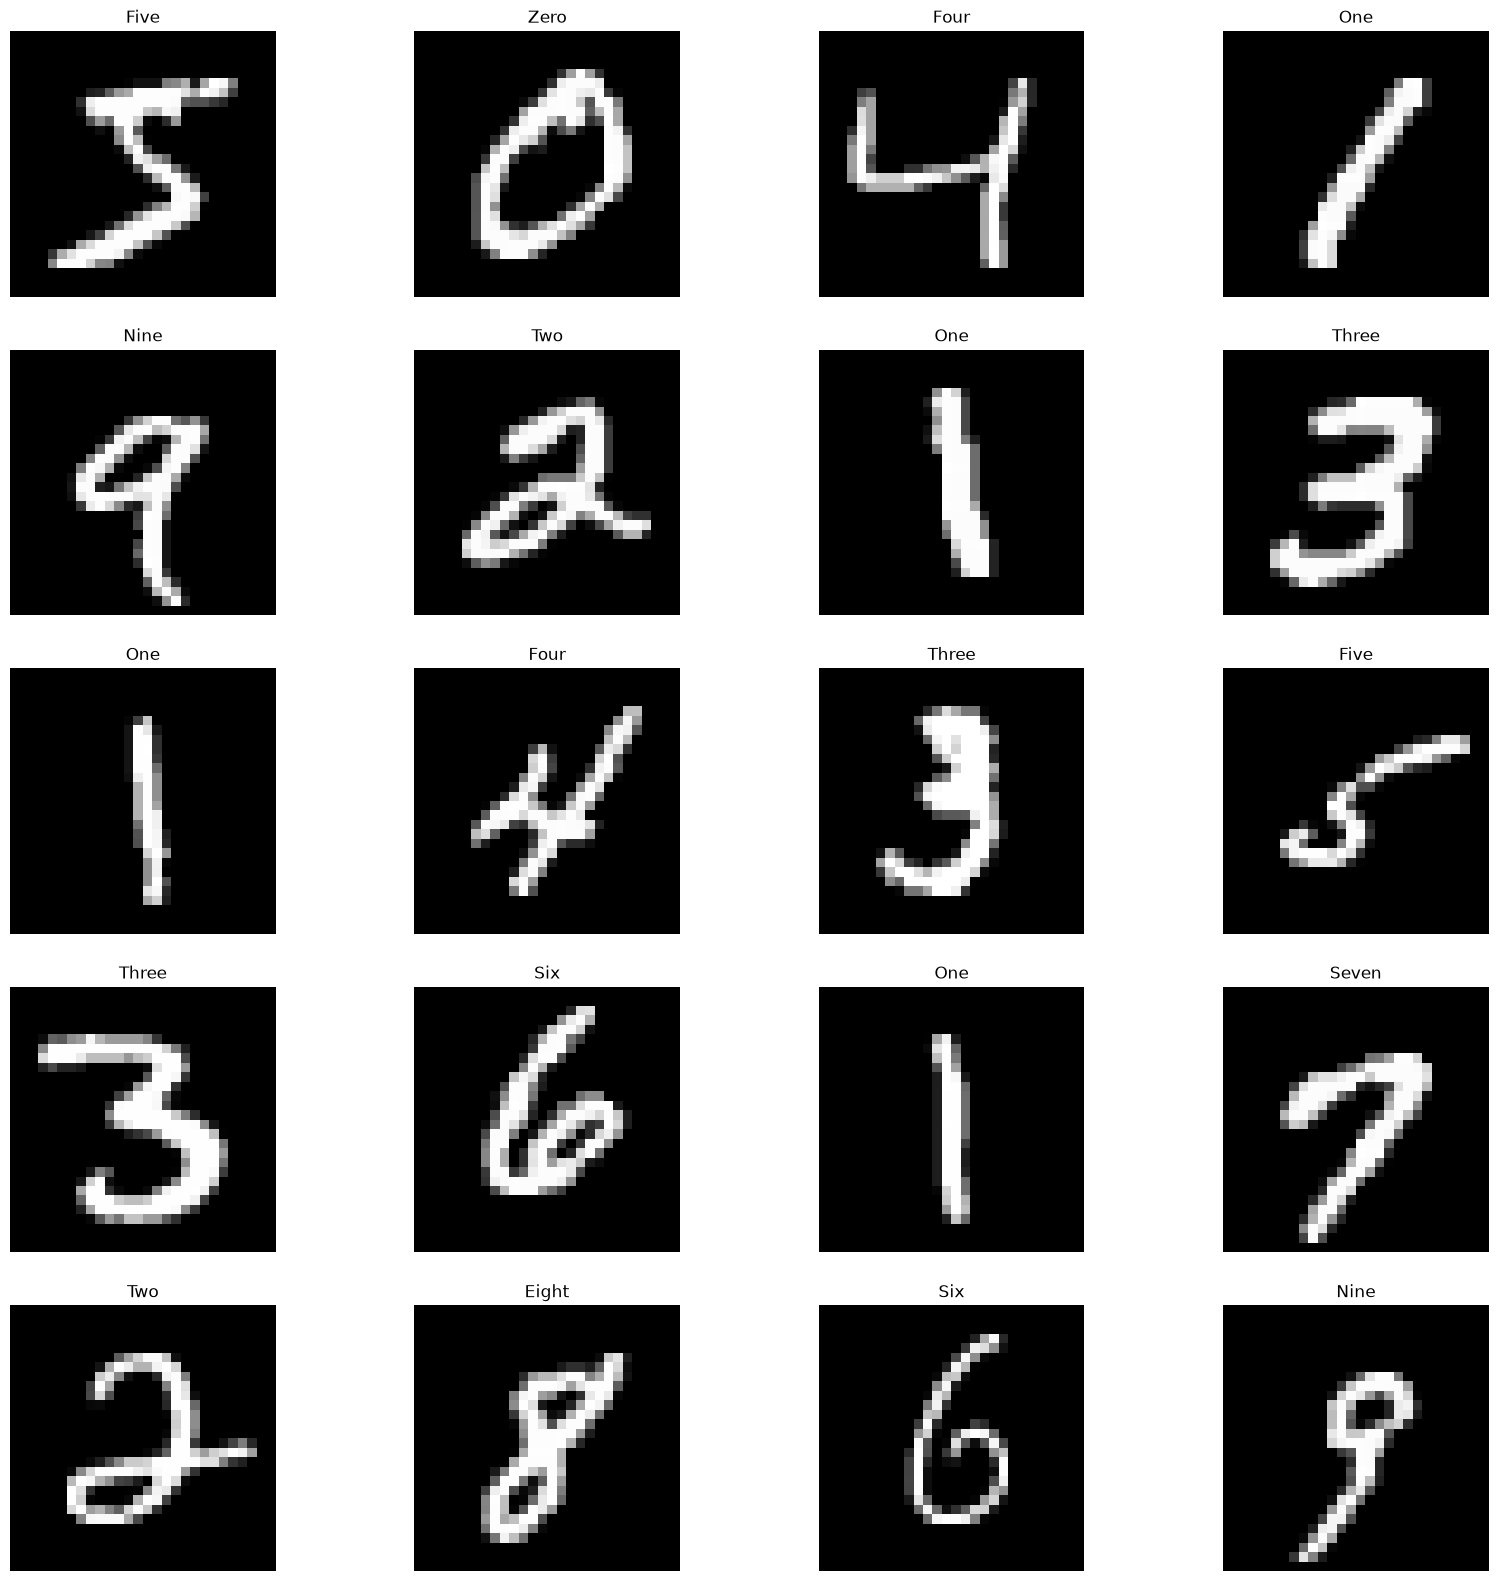

In [18]:
mnist_names = [
    "Zero", "One", "Two", "Three", "Four",
    "Five", "Six", "Seven", "Eight", "Nine"
]
plt.figure(figsize=(20, 20))
for i in range(20):
    plt.subplot(5, 4, i + 1)
    plt.axis('off')
    plt.grid(False)
    plt.imshow(x_train_digit[i], cmap='gray')
    plt.title(mnist_names[y_train_digit[i]])
    y_train_digit[i] = 5
    mnist_names[5]
plt.show()

In [19]:
x_train_digit=x_train_digit.reshape(60000,784)
x_test_digit=x_test_digit.reshape(10000,784)

In [20]:
y_train_digit = to_categorical(y_train_digit,num_classes=10)
y_test_digit = to_categorical(y_test_digit,num_classes=10)

In [29]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(256, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [30]:
history = model.fit(
    x_train_digit,
    y_train_digit,
    batch_size=100,
    epochs=10,
    validation_data=(x_test_digit,y_test_digit)
)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7814 - loss: 1.9557 - val_accuracy: 0.8661 - val_loss: 0.5190
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8949 - loss: 0.3919 - val_accuracy: 0.9194 - val_loss: 0.3469
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9298 - loss: 0.2605 - val_accuracy: 0.9240 - val_loss: 0.2993
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9439 - loss: 0.2088 - val_accuracy: 0.9435 - val_loss: 0.2385
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9543 - loss: 0.1689 - val_accuracy: 0.9466 - val_loss: 0.2330
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9607 - loss: 0.1373 - val_accuracy: 0.9518 - val_loss: 0.2043
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9662 - loss: 0.1196 - val_accuracy: 0.9571 - val_loss: 0.2208
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9687 - loss: 0.1085 - val_accuracy: 0.

In [31]:
y_predict = model.predict(x_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [35]:
y_predict[2]

array([0.0000000e+00, 9.9999994e-01, 9.1258367e-29, 8.9064392e-16,
       4.9476613e-15, 9.8793040e-10, 7.9583789e-32, 9.6116537e-10,
       7.6177834e-18, 4.2019098e-15], dtype=float32)

In [37]:
import numpy as np
y_predicted = np.argmax(y_predict, axis=1)

In [40]:
y_actual = np.argmax(y_test_digit, axis=1)

print("Actual:", y_actual[0])
print("Predicted:", y_predicted[0])

Actual: 7
Predicted: 7


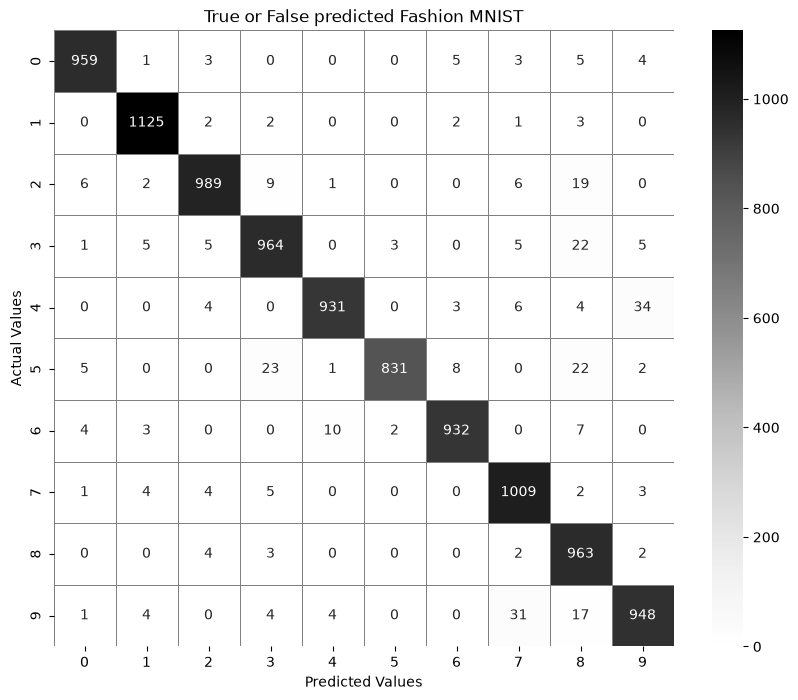

In [41]:
cm = confusion_matrix(y_actual, y_predicted)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    cmap='Greys',
    fmt='d',
    linewidths=0.5,
    linecolor='gray'
)
plt.title('True or False predicted Fashion MNIST')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

In [43]:
cm = confusion_matrix(y_actual, y_predicted)
cm

array([[ 959,    1,    3,    0,    0,    0,    5,    3,    5,    4],
       [   0, 1125,    2,    2,    0,    0,    2,    1,    3,    0],
       [   6,    2,  989,    9,    1,    0,    0,    6,   19,    0],
       [   1,    5,    5,  964,    0,    3,    0,    5,   22,    5],
       [   0,    0,    4,    0,  931,    0,    3,    6,    4,   34],
       [   5,    0,    0,   23,    1,  831,    8,    0,   22,    2],
       [   4,    3,    0,    0,   10,    2,  932,    0,    7,    0],
       [   1,    4,    4,    5,    0,    0,    0, 1009,    2,    3],
       [   0,    0,    4,    3,    0,    0,    0,    2,  963,    2],
       [   1,    4,    0,    4,    4,    0,    0,   31,   17,  948]])

In [44]:
from sklearn.metrics import classification_report
print(classification_report(y_actual, y_predicted))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       980
           1       0.98      0.99      0.99      1135
           2       0.98      0.96      0.97      1032
           3       0.95      0.95      0.95      1010
           4       0.98      0.95      0.97       982
           5       0.99      0.93      0.96       892
           6       0.98      0.97      0.98       958
           7       0.95      0.98      0.97      1028
           8       0.91      0.99      0.95       974
           9       0.95      0.94      0.94      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.96      0.96     10000
weighted avg       0.97      0.97      0.97     10000



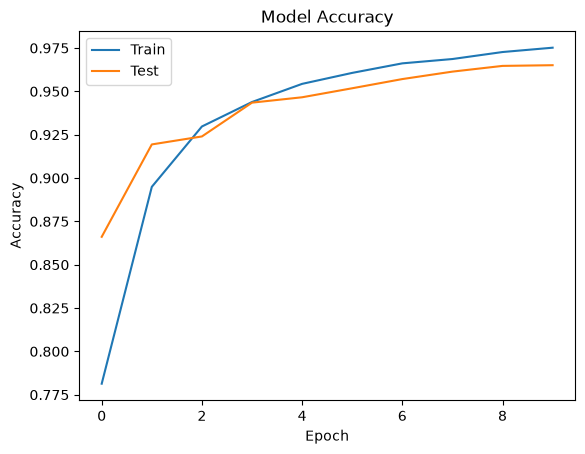

In [45]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

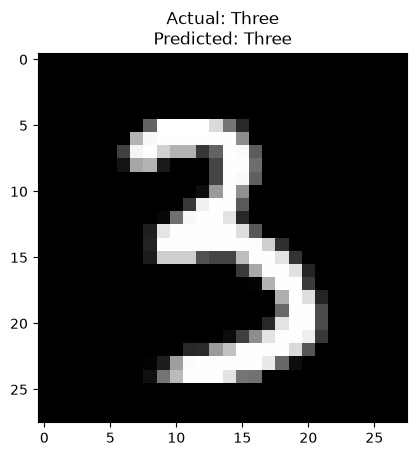

In [47]:
mnist_names = [
    "Zero", "One", "Two", "Three", "Four",
    "Five", "Six", "Seven", "Eight", "Nine"
]
index = 32
plt.imshow(x_test_digit[index].reshape(28, 28), cmap='gray')
actual = np.argmax(y_test_digit[index])
predicted = np.argmax(y_predict[index])
plt.title(
    f"Actual: {mnist_names[actual]}\n"
    f"Predicted: {mnist_names[predicted]}"
)
plt.show()
